In [1]:
import pyuvdata
import matplotlib.pyplot as plt
import matplotlib
import numpy as np

In [2]:
def detrend(x, y, deg=1):
    idx = np.isfinite(x) & np.isfinite(y)
    fit_coeffs = np.polyfit(x[idx], y[idx], deg)
    polyfit_function = np.poly1d(fit_coeffs)
    y_new = y - polyfit_function(x)
    return y_new

def detrend_ratio(x, y):
    idx = np.isfinite(x) & np.isfinite(y)
    m, b = np.polyfit(x[idx], y[idx], 1)
    y_new = y / (m*x + b)
    return y_new

In [3]:
uv = pyuvdata.UVData()
uv.read("/lustre/rbyrne/2026-04-19/20260419_34MHz_autocorrs.ms")

In [14]:
uv.flag_array[np.where(uv.data_array == 0)] = True
uv.data_array[np.where(uv.flag_array)] = np.nan + 1j*np.nan

In [4]:
lsts = pyuvdata.utils.get_lst_for_time(jd_array=uv.time_array, telescope_loc=uv.telescope.location) / np.pi * 12

In [5]:
lsts

array([14.45661619, 14.45661619, 14.45661619, ..., 11.94758303,
       11.94758303, 11.94758303], shape=(418176,))

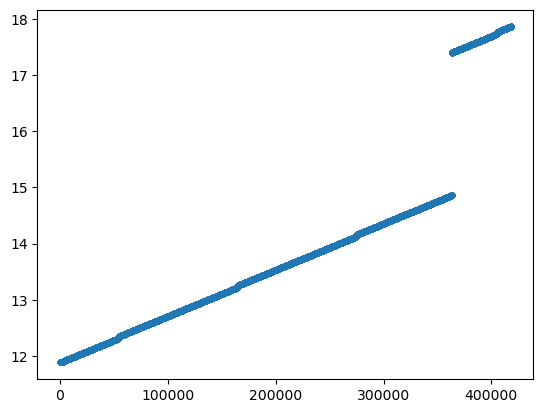

In [6]:
plt.plot(np.sort(lsts), ".")

In [7]:
uv.select(times=uv.time_array[np.where(lsts < 16)], inplace=True)  # Keep only contiguous times

In [15]:
uv_single = uv.select(times=np.min(uv.time_array), antenna_names=["LWA023"], inplace=False)

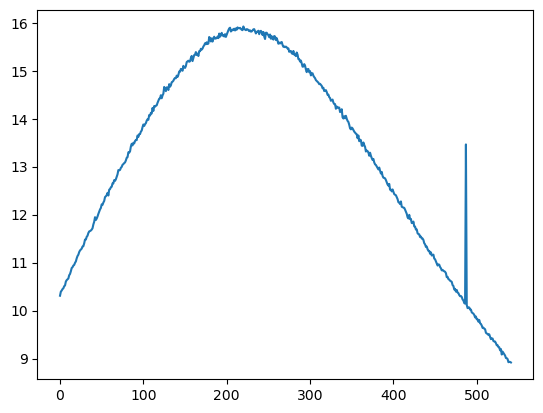

In [17]:
plt.plot(uv_single.data_array[0, :, 0])

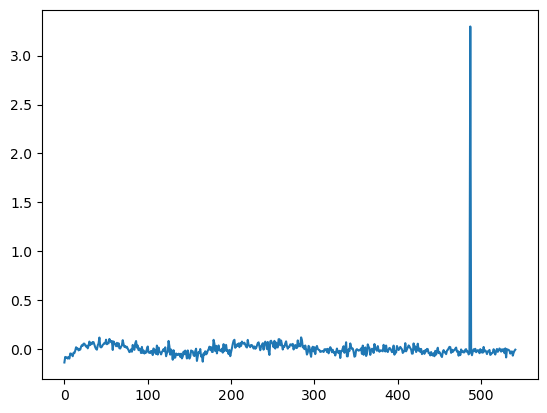

In [ ]:
spec_detrended = detrend(uv_single.freq_array, uv_single.data_array[0, :, 0], deg=5)
plt.plot(spec_detrended)

Casting complex values to real discards the imaginary part
Casting complex values to real discards the imaginary part


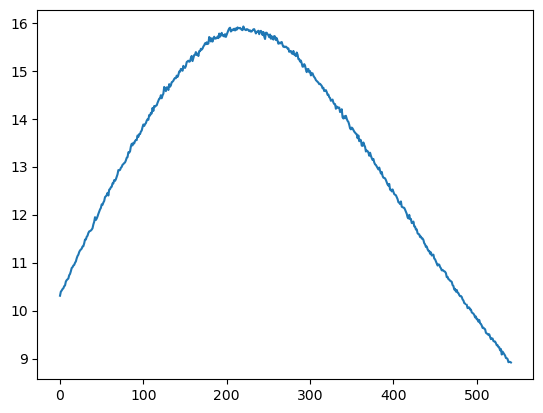

In [23]:
flags = np.where(spec_detrended > 10*np.std(spec_detrended))[0]
uv_single.flag_array[0, flags, 0] = True
uv_single.data_array[0, flags, 0] = np.nan + 1j*np.nan
plt.plot(uv_single.data_array[0, :, 0])

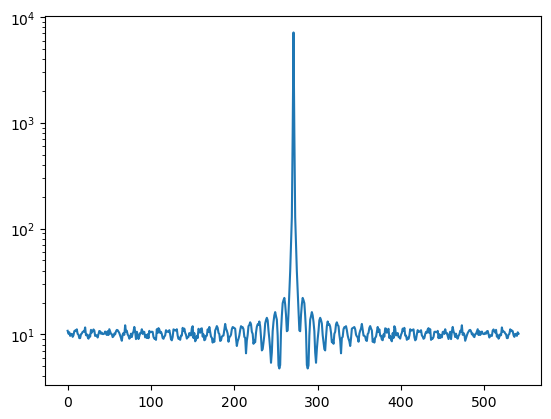

In [29]:
spec_masked = uv_single.data_array[0, :, 0]
spec_masked[np.where(~np.isfinite(spec_masked))] = 0 + 1j*0
plt.plot(np.abs(np.fft.fftshift(np.fft.fft(spec_masked))))
plt.yscale("log")

In [ ]:
min_val = 0
max_val = 15
norm = matplotlib.colors.Normalize(vmin=min_val, vmax=max_val, clip=True)
mapper = matplotlib.cm.ScalarMappable(norm=norm, cmap=matplotlib.cm.inferno_r)

for antenna_name in [uv.telescope.antenna_names[0]]:
    fig, ax = plt.subplots(figsize=(6,30), dpi=120)
    uv_single_ant = uv.select(antenna_names=[antenna_name], polarizations=[-5], inplace=False)
    uv_single_ant.data_array[np.where(uv_single_ant.flag_array)] = np.nan + 1j*np.nan
    uv_single_ant.reorder_blts(order="time")

    offset=0
    for time_ind in range(uv_single_ant.Ntimes):
        #spec_detrended = detrend(uv_single_ant.freq_array, np.abs(uv_single_ant.data_array[time_ind, :, 0]), deg=4)
        spec_detrended = np.abs(uv_single_ant.data_array[time_ind, :, 0])
        spec_detrended_scaled = spec_detrended / (max_val-min_val) * 0.001 + uv_single_ant.time_array[time_ind]
        for point_ind in range(len(spec_detrended)):
            ax.plot(
                uv_single_ant.freq_array[point_ind] / 1e6,
                spec_detrended_scaled[point_ind],
                ".",
                markersize=1,
                linewidth=0.1, 
                color=mapper.to_rgba(spec_detrended[point_ind]),
                alpha=0.5,
            )
            if point_ind != 0:
                ax.plot(
                    uv_single_ant.freq_array[point_ind-1:point_ind+1] / 1e6,
                    spec_detrended_scaled[point_ind-1:point_ind+1],
                    "-",
                    markersize=1,
                    linewidth=0.1, 
                    color=mapper.to_rgba(np.mean(spec_detrended[point_ind-1:point_ind+1])),
                    alpha=0.5,
                )
    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Time (JD)")
    fig.colorbar(mapper, ax=ax, label="Spectrum Value")
    ax.set_title(antenna_name)
    plt.show()

Polyfit may be poorly conditioned


KeyboardInterrupt: 

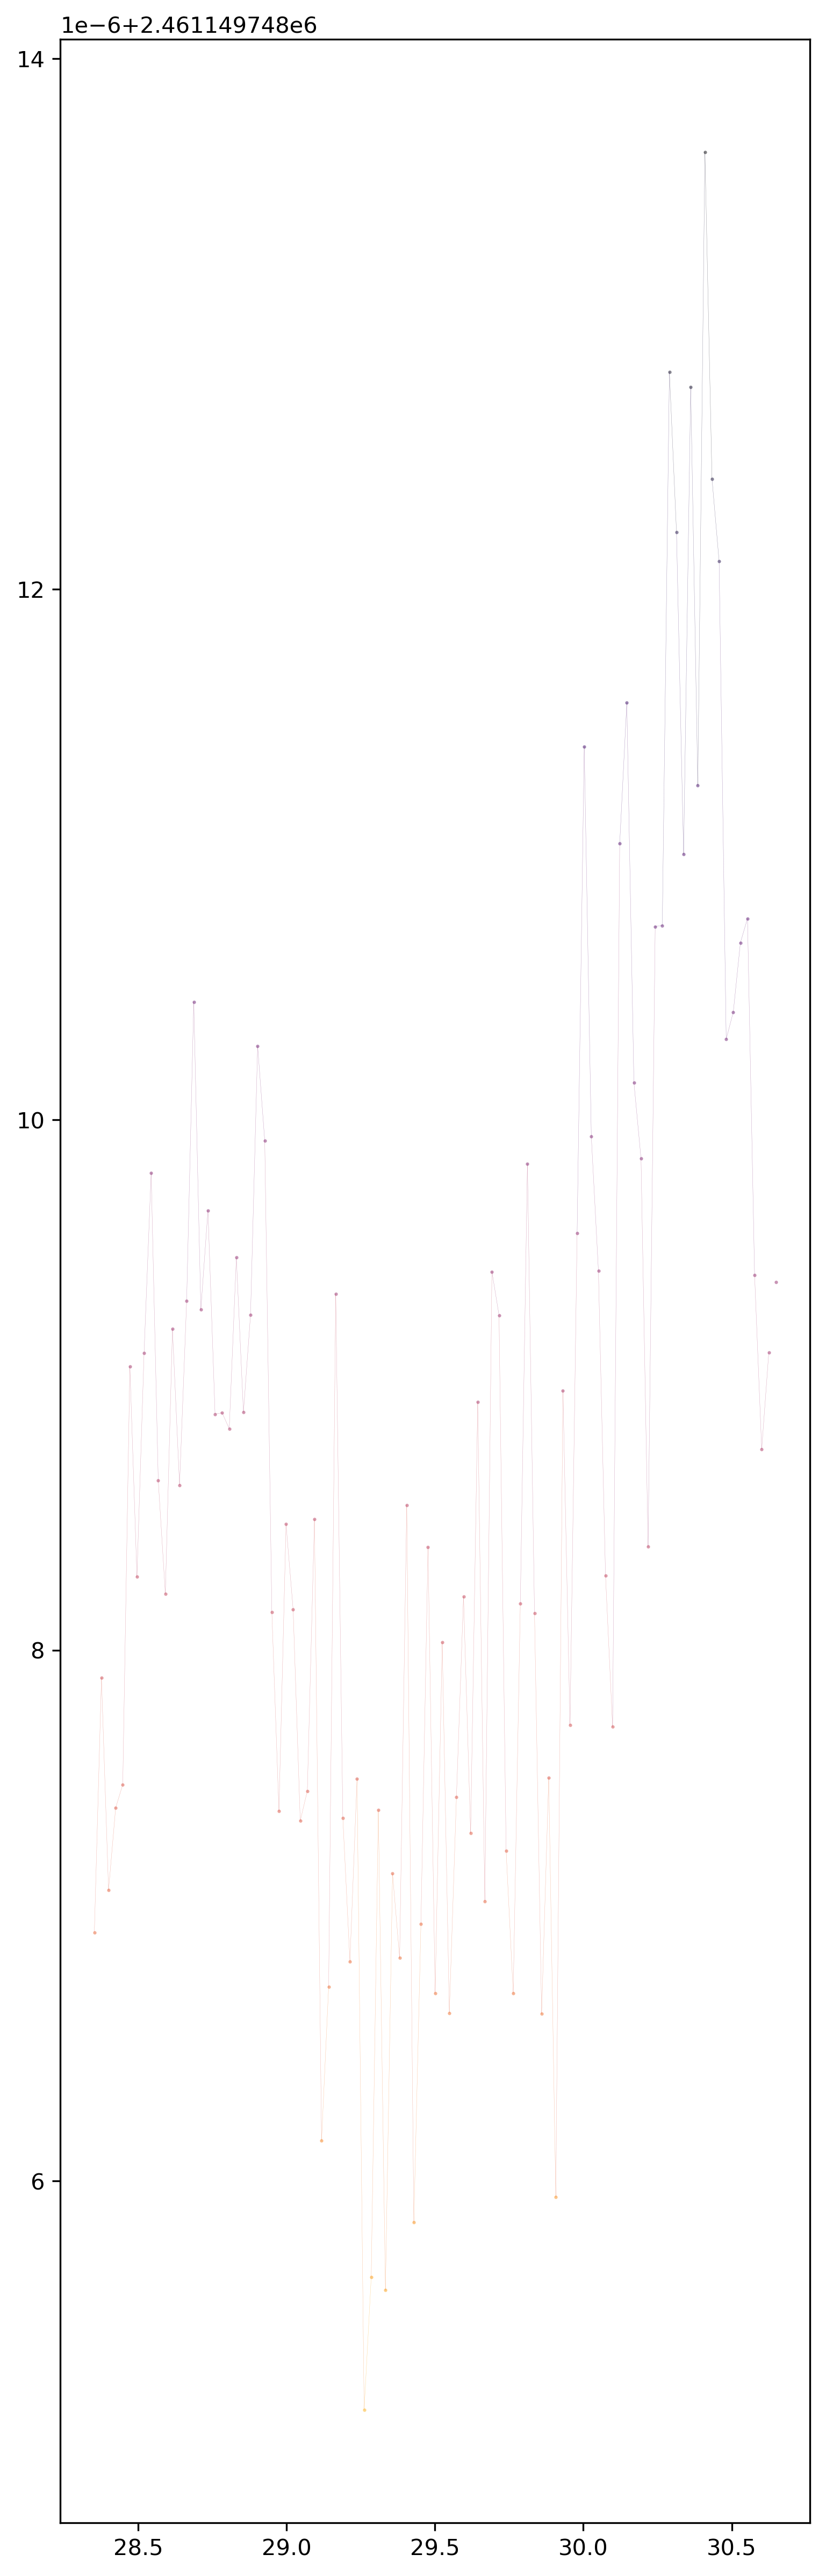

In [ ]:
min_val = -0.1
max_val = 0.1
norm = matplotlib.colors.Normalize(vmin=min_val, vmax=max_val, clip=True)
mapper = matplotlib.cm.ScalarMappable(norm=norm, cmap=matplotlib.cm.inferno_r)

for antenna_name in [uv.telescope.antenna_names[0]]:
    fig, ax = plt.subplots(figsize=(6,20), dpi=300)
    uv_single_ant = uv.select(antenna_names=[antenna_name], polarizations=[-5], inplace=False)
    uv_single_ant.data_array[np.where(uv_single_ant.flag_array)] = np.nan + 1j * np.nan
    uv_single_ant.reorder_blts(order="time")

    offset=0
    for time_ind in range(360):
        spec_detrended = detrend(uv_single_ant.freq_array, np.abs(uv_single_ant.data_array[time_ind, :, 0]), deg=10)
        #spec_detrended = np.abs(uv_single_ant.data_array[time_ind, :, 0])
        spec_detrended_scaled = spec_detrended / (max_val-min_val) * 0.0001 + uv_single_ant.time_array[time_ind]
        for point_ind in range(len(spec_detrended)):
            ax.plot(
                uv_single_ant.freq_array[point_ind] / 1e6,
                spec_detrended_scaled[point_ind],
                ".",
                markersize=1,
                linewidth=0.1, 
                color=mapper.to_rgba(spec_detrended[point_ind]),
                alpha=0.5,
            )
            if point_ind != 0:
                ax.plot(
                    uv_single_ant.freq_array[point_ind-1:point_ind+1] / 1e6,
                    spec_detrended_scaled[point_ind-1:point_ind+1],
                    "-",
                    markersize=1,
                    linewidth=0.1, 
                    color=mapper.to_rgba(np.mean(spec_detrended[point_ind-1:point_ind+1])),
                    alpha=0.5,
                )
    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Time (JD)")
    fig.colorbar(mapper, ax=ax, label="Spectrum Value")
    ax.set_title(antenna_name)
    plt.show()

In [ ]:
filepath = "/lustre/pipeline/cosmology/concatenated_data/34MHz/2026-04-19/11/20260419_112643-112833_34MHz.ms"
uv = pyuvdata.UVData()
uv.read(filepath)
uv.select(ant_str="auto", inplace=True)

In [ ]:
np.shape(uv.data_array)

(4224, 542, 4)

In [ ]:
uv.telescope.antenna_positions
with open('/fast/rbyrne/ovro_lwa_antlocs.npy', 'wb') as f:
    np.save(f, uv.telescope.antenna_positions)
    np.save(f, uv.telescope.antenna_names)

In [ ]:
with open('/fast/rbyrne/ovro_lwa_antlocs.npy', 'rb') as f:
    antpos = np.load(f)
    antnames = np.load(f)

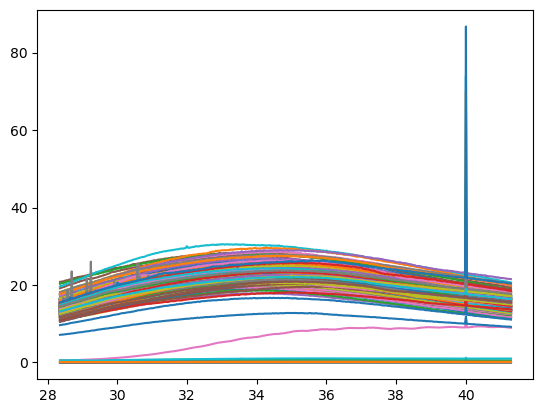

In [ ]:
for ant_name in np.sort(uv.telescope.antenna_names):
    uv_single_ant = uv.select(antenna_names=[ant_name], times=np.min(uv.time_array), inplace=False)
    plt.plot(uv_single_ant.freq_array / 1e6, np.abs(uv_single_ant.data_array[0, :, 0]), label=ant_name)
plt.show()

In [ ]:
uv_single_time = uv.select(times=[np.min(uv.time_array)], inplace=False)

Text(0, 0.5, 'Antenna Index')

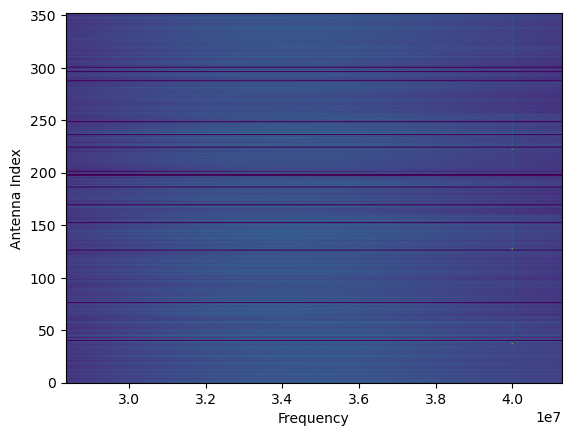

In [ ]:
plt.imshow(
    np.abs(uv_single_time.data_array[:, :, 0]),
    origin="lower",
    interpolation=None,
    extent=[np.min(uv_single_time.freq_array), np.max(uv_single_time.freq_array), 0, uv_single_time.Nants_data],
    aspect='auto',
)
plt.xlabel("Frequency")
plt.ylabel("Antenna Index")

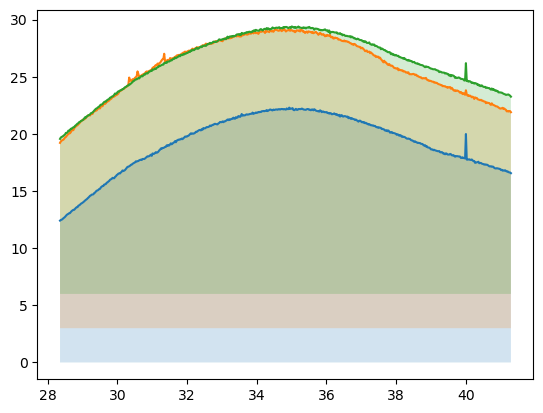

In [ ]:
offset = 0
#for ant_ind in range(uv_single_time.Nants_data):
for ant_ind in range(3):
    plt.plot(
        uv_single_time.freq_array / 1e6,
        np.abs(uv_single_time.data_array[ant_ind, :, 0]) + offset,
    )
    plt.fill_between(
        x=uv_single_time.freq_array / 1e6, 
        y1=np.zeros_like(uv_single_time.freq_array) + offset,
        y2=np.abs(uv_single_time.data_array[ant_ind, :, 0]) + offset,
        alpha= 0.2
    )
    offset += 3

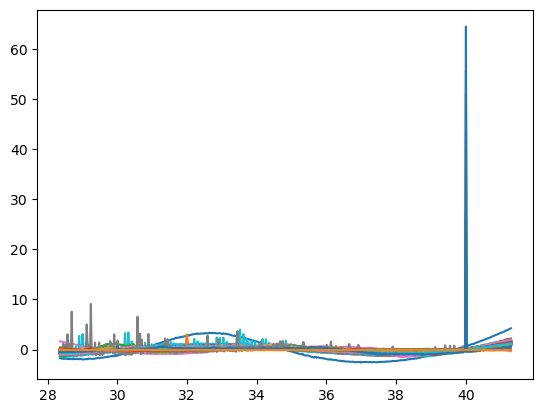

In [ ]:
for ant_name in np.sort(uv.telescope.antenna_names):
    uv_single_ant = uv.select(antenna_names=[ant_name], times=np.min(uv.time_array), inplace=False)
    autocorrs_detrended = detrend(uv_single_ant.freq_array/1e6, np.abs(uv_single_ant.data_array[0, :, 0]), deg=2)
    plt.plot(uv_single_ant.freq_array / 1e6, autocorrs_detrended, label=ant_name)
plt.show()

In [ ]:
delay_array_s = np.fft.fftshift(
    np.fft.fftfreq(len(uv.freq_array), d=np.mean(uv.channel_width))
)
autos_fft = np.fft.fftshift(np.fft.fft(uv.data_array, axis=1), axes=1)

In [ ]:
np.shape(autos_fft)

(4224, 542, 4)

Casting complex values to real discards the imaginary part
Casting complex values to real discards the imaginary part


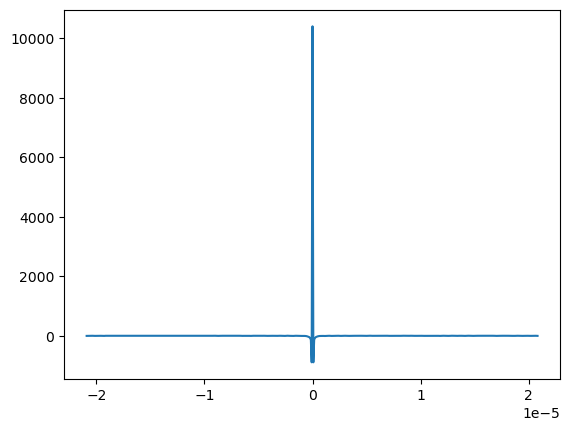

In [ ]:
plt.plot(delay_array_s, autos_fft[0, :, 0])

Casting complex values to real discards the imaginary part
Casting complex values to real discards the imaginary part


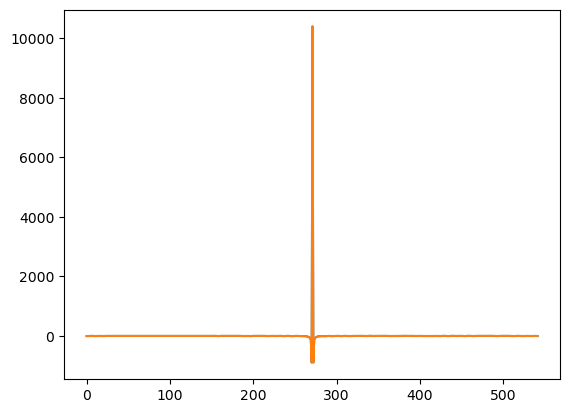

In [ ]:
plt.plot(np.fft.fftshift(np.fft.fft(uv.data_array[0, :, 0])))
plt.plot(np.fft.fftshift(np.fft.fft(np.abs(uv.data_array[0, :, 0]))))

In [ ]:
uv.telescope.location

<EarthLocation (-2409247.20369628, -4477889.56236559, 3839327.82827939) m>